**PoCT - Toxoplasmosis Diagnosis Device (Dec, 2026)**  
Dodit Suprianto  
Email: Dodit.suprianto@polinema.ac.id  
Affiliation:  
- Department of Electrical Engineering, Politeknik Negeri Malang, Malang, Indonesia  
- AIDS, Toxoplasma, Opportunistic Disease and Malaria (ATOM) Research Group, Faculty of Medicine, Universitas Brawijaya, Malang, Indonesia

---

# Figure 5 – segmentation example (YOLOv8n-seg, dot-blot)
Renders a clean, publication-style example for the manuscript: **(a)** ground-truth masks and **(b)** predictions of the trained `best.pt` on one **validation** image, with the per-spot confidence and a spot-level match to the ground truth (mask IoU ≥ 0.5, one-to-one).

**Before running:** the notebook reads the image and label directly from `dataset/validation` and the weights from `yolo_results/dotblot-yolov8n-seg/weights/best.pt` of the folder *DotBlot YOLO Segmentation* (Colab Drive folder, the current folder, or the folder given by the environment variable `DOTBLOT_YOLO_ROOT`). Only the *Config* cell may need editing. Output goes to `figures/` of the same folder.
Runtime → *Change runtime type* → GPU is optional (one image only).

In [1]:
try:
    import ultralytics
except ImportError:
    %pip -q install "ultralytics==8.4.208"
try:                                   # Colab only: mount Drive; elsewhere the local folders are used
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass


Mounted at /content/drive


## 1. Config

In [2]:
from pathlib import Path
import os, tempfile

def _find_root():
    # Resolution order: (1) environment variable DOTBLOT_YOLO_ROOT, (2) Colab Drive folder, (3) current folder, its sub-folder or parent.
    # ROOT is the folder that contains dataset/train, dataset/validation and dataset/test ("DotBlot YOLO Segmentation" in the repository).
    env = os.environ.get('DOTBLOT_YOLO_ROOT')
    cands = [Path(env)] if env else []
    cands += [Path('/content/drive/MyDrive/DotBlot YOLO Segmentation'), Path('/content/drive/MyDrive/DotBlot FKUB'),
              Path.cwd(), Path.cwd()/'DotBlot YOLO Segmentation', Path.cwd().parent]
    for c in cands:
        if (c/'dataset'/'train'/'images').exists() and (c/'dataset'/'validation'/'images').exists(): return c
    raise FileNotFoundError('Dataset not found. Set the environment variable DOTBLOT_YOLO_ROOT to the folder that contains dataset/train and dataset/validation.')

ROOT       = _find_root()
VAL_DIR    = ROOT/'dataset'/'validation'            # images/Validation + labels/Validation (read in place, no zip)
RUN_NAME   = 'dotblot-yolov8n-seg'
# Weights of the manuscript run; override with the environment variable DOTBLOT_WEIGHTS to use another file.
WEIGHTS    = Path(os.environ['DOTBLOT_WEIGHTS']) if 'DOTBLOT_WEIGHTS' in os.environ else ROOT/'yolo_results'/RUN_NAME/'weights'/'best.pt'
STEMS      = ['raw_capture_20251127_145246_534104_1410389c']   # validation image(s) to draw (file name without extension)
IMGSZ, CONF, IOU_MATCH = 1920, 0.5, 0.5
OUT_DIR    = Path(os.environ.get('DOTBLOT_FIG_DIR', ROOT/'figures')); OUT_DIR.mkdir(exist_ok=True)
WORK       = Path(tempfile.gettempdir())/'fig5_work'; WORK.mkdir(exist_ok=True)


## 2. Locate weights and extract the chosen validation image with its label

In [3]:
import shutil
assert Path(WEIGHTS).exists(), f'best.pt not found at {WEIGHTS}; set DOTBLOT_WEIGHTS to the weights file.'
print('weights:', WEIGHTS)
found = {}
for p in VAL_DIR.rglob('*'):
    if p.is_file() and p.stem in STEMS and p.suffix.lower() in ('.png','.jpg','.jpeg','.txt'):
        dst = WORK/p.name; shutil.copy2(p, dst); found.setdefault(p.stem, {})['lab' if p.suffix.lower()=='.txt' else 'img'] = dst
for s in STEMS: print(s, '->', {k: v.name for k, v in found.get(s, {}).items()})
assert all(len(found.get(s, {}))==2 for s in STEMS), 'image or label missing in dataset/validation (check STEMS)'


weights: /content/drive/MyDrive/DotBlot FKUB/yolo_results/dotblot-yolov8n-seg/weights/best.pt
raw_capture_20251127_145246_534104_1410389c -> {'lab': 'raw_capture_20251127_145246_534104_1410389c.txt', 'img': 'raw_capture_20251127_145246_534104_1410389c.png'}


## 3. Predict and match to ground truth

In [4]:
import numpy as np, cv2
from ultralytics import YOLO
model = YOLO(str(WEIGHTS))
S = 0.5    # raster scale for IoU

def read_polys(lab, w, h):
    out = []
    for ln in Path(lab).read_text().splitlines():
        t = ln.split()
        if len(t) >= 7: out.append(np.array(t[1:], float).reshape(-1, 2) * [w, h])
    return out
def raster(poly, w, h):
    m = np.zeros((int(h*S), int(w*S)), np.uint8); cv2.fillPoly(m, [np.round(poly*S).astype(np.int32)], 1); return m.astype(bool)

def analyse(stem):
    img = cv2.imread(str(found[stem]['img']), cv2.IMREAD_GRAYSCALE); h, w = img.shape
    gt = read_polys(found[stem]['lab'], w, h)
    r = model.predict(str(found[stem]['img']), imgsz=IMGSZ, conf=CONF, iou=0.45, verbose=False)[0]
    pr = [np.asarray(p) for p in (r.masks.xy if r.masks is not None else [])]; sc = r.boxes.conf.cpu().numpy() if len(pr) else np.array([])
    gm, pm = [raster(p, w, h) for p in gt], [raster(p, w, h) for p in pr]
    M = np.array([[ (a&b).sum()/max((a|b).sum(), 1) for b in gm] for a in pm]).reshape(len(pm), len(gm))
    pairs = sorted([(M[i, j], i, j) for i in range(len(pm)) for j in range(len(gm)) if M[i, j] >= IOU_MATCH], reverse=True)
    up, ug, tp = set(), set(), []
    for v, i, j in pairs:
        if i not in up and j not in ug: up.add(i); ug.add(j); tp.append((i, j))
    fp = [i for i in range(len(pm)) if i not in up]; fn = [j for j in range(len(gm)) if j not in ug]
    return img, gt, pr, sc, up, fp, fn

res = {s: analyse(s) for s in STEMS}
for s, (img, gt, pr, sc, up, fp, fn) in res.items():
    print(f'{s}: ground-truth spots {len(gt)}, predicted {len(pr)}, TP {len(up)}, FP {len(fp)}, FN {len(fn)}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
raw_capture_20251127_145246_534104_1410389c: ground-truth spots 25, predicted 22, TP 22, FP 0, FN 3


## 4. Figure

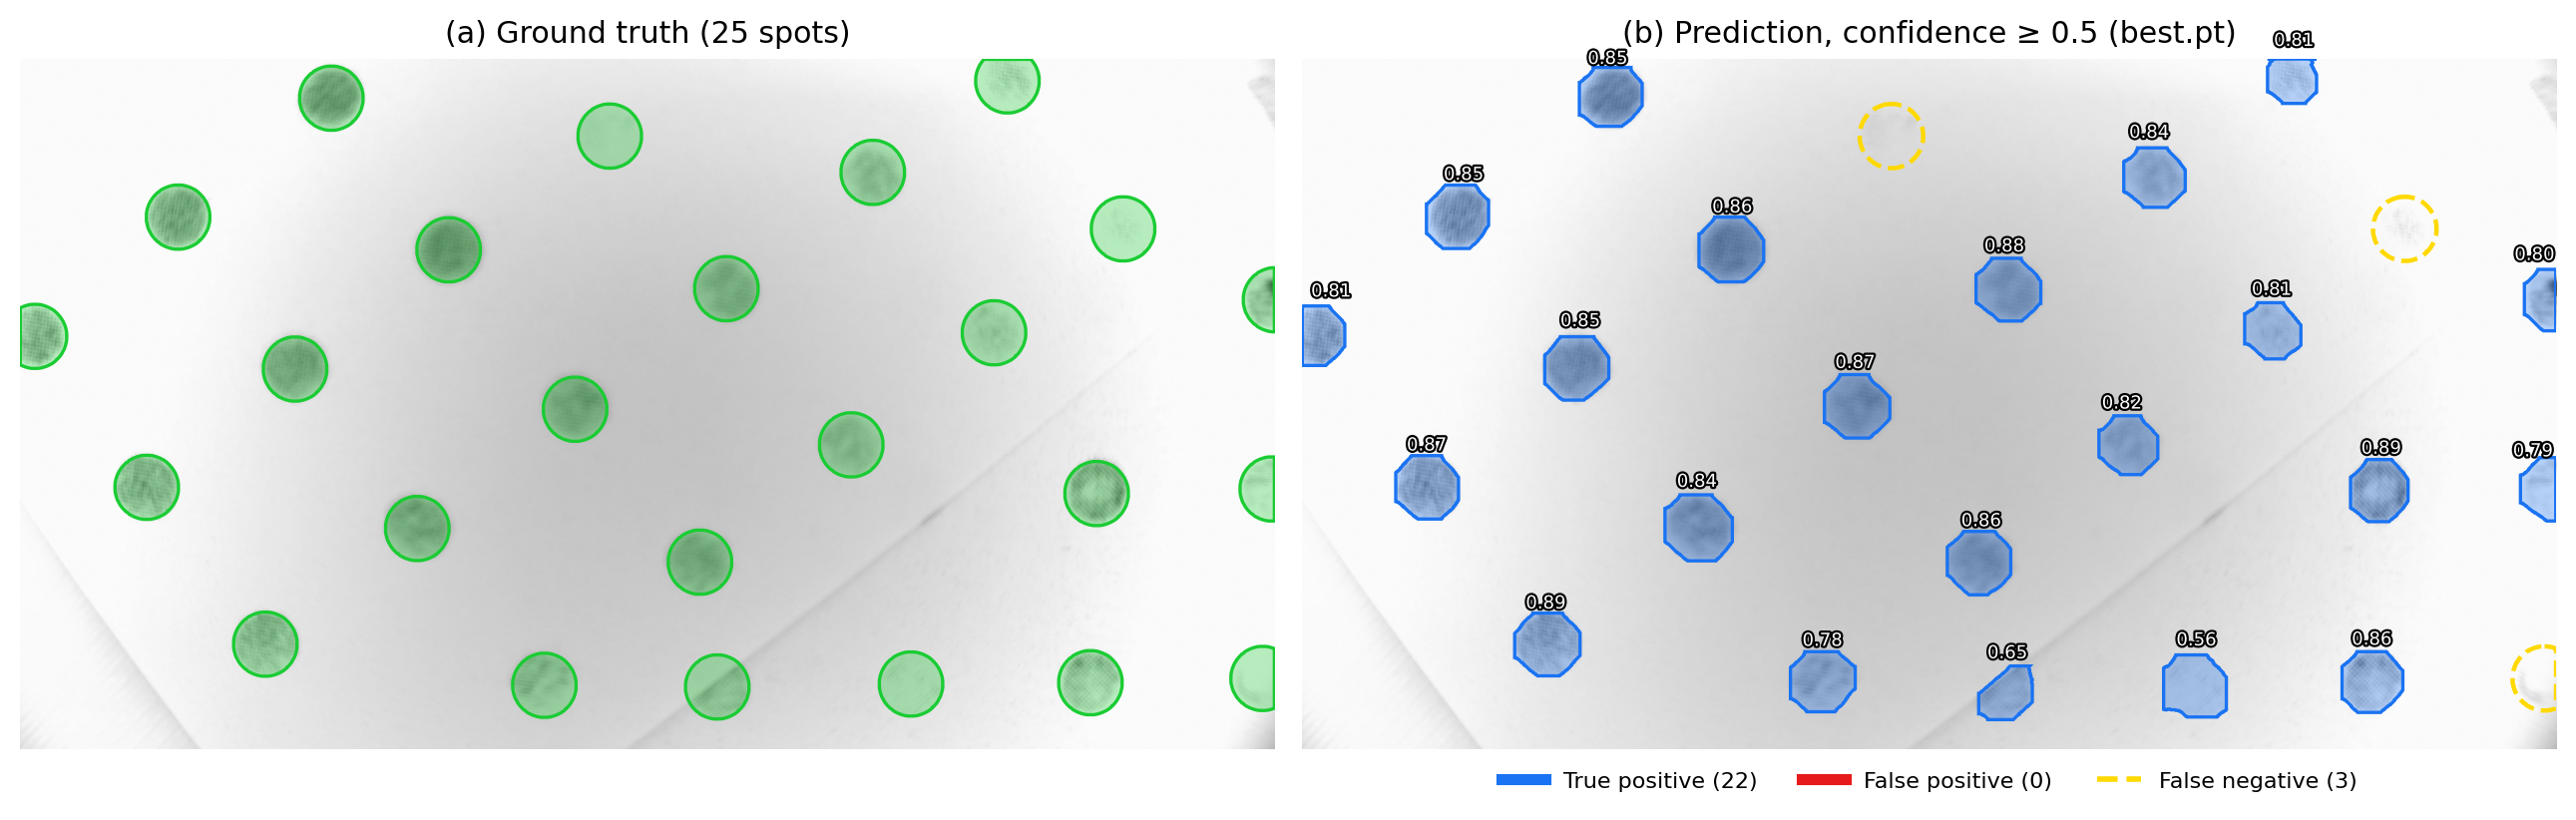

saved: /content/drive/MyDrive/DotBlot FKUB/figures/Figure5_segmentation_raw_capture_20251127_145246_534104_1410389c.png


In [5]:
import matplotlib; import matplotlib.pyplot as plt, matplotlib.patheffects as pe
from matplotlib.patches import Polygon
plt.rcParams.update({'font.size': 9})
def draw(stem):
    img, gt, pr, sc, up, fp, fn = res[stem]
    allp = np.vstack(gt + pr); pad = 90
    x0, y0 = np.maximum(allp.min(0) - pad, 0).astype(int); x1, y1 = np.minimum(allp.max(0) + pad, [img.shape[1], img.shape[0]]).astype(int)
    fig, ax = plt.subplots(1, 2, figsize=(13, 13*(y1-y0)/(x1-x0)/2 + .6), dpi=200)
    for a in ax: a.imshow(img, cmap='gray', vmin=0, vmax=255); a.set_xlim(x0, x1); a.set_ylim(y1, y0); a.axis('off')
    for p in gt: ax[0].add_patch(Polygon(p, closed=True, fc=(0.1, 0.8, 0.2, .30), ec=(0.1, 0.8, 0.2), lw=1.2))
    for i, p in enumerate(pr):
        ok = i in up; col = (0.1, 0.45, 0.95) if ok else (0.9, 0.1, 0.1)
        ax[1].add_patch(Polygon(p, closed=True, fc=col+(.30,), ec=col, lw=1.2))
        cx, cy = p.mean(0); ax[1].text(cx, cy - 0.5*np.ptp(p[:, 1]) - 8, f'{sc[i]:.2f}', color='white', ha='center', va='bottom', fontsize=6.5,
                                       path_effects=[pe.withStroke(linewidth=1.6, foreground='black')])
    for j in fn: ax[1].add_patch(Polygon(gt[j], closed=True, fill=False, ec=(1, .85, 0), lw=1.6, ls='--'))
    ax[0].set_title(f'(a) Ground truth ({len(gt)} spots)'); ax[1].set_title(f'(b) Prediction, confidence ≥ {CONF} (best.pt)')
    from matplotlib.lines import Line2D
    ax[1].legend(handles=[Line2D([], [], color=(0.1, 0.45, 0.95), lw=4, label=f'True positive ({len(up)})'), Line2D([], [], color=(0.9, 0.1, 0.1), lw=4, label=f'False positive ({len(fp)})'),
                          Line2D([], [], color=(1, .85, 0), lw=2, ls='--', label=f'False negative ({len(fn)})')], loc='lower center', bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False, fontsize=8)
    plt.tight_layout(); out = OUT_DIR/f'Figure5_segmentation_{stem}.png'; plt.savefig(out, bbox_inches='tight'); plt.show(); print('saved:', out)
for s in STEMS: draw(s)

## 5. Notes for the caption
Suggested caption: *Automated segmentation of a held-out validation membrane image: (a) ground-truth masks and (b) YOLOv8-seg predictions (best.pt, confidence ≥ 0.5; value = confidence). Blue, true positive (mask IoU ≥ 0.5); red, false positive; dashed yellow, missed ground-truth spot.* Adjust the counts to the printed TP/FP/FN. To draw other images, add stems to `STEMS` (validation images only).